In [1]:
# Load and get an overview
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_theme(style="whitegrid")

df = pd.read_csv("data/Titanic-Dataset.csv")
print("Shape:", df.shape)
df.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
df.info()
print(df.isnull().sum())


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [3]:
# Summary statistics (Hint 1)

df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [4]:
num_cols = ["Age", "Fare", "SibSp", "Parch"]
stats = df[num_cols].agg(["mean", "median", "std", "min", "max", "skew"]).round(2)
stats

,Age,Fare,SibSp,Parch
mean,29.70,32.20,0.52,0.38
median,28.00,14.45,0.00,0.00
std,14.53,49.69,1.10,0.81
min,0.42,0.00,0.00,0.00
max,80.00,512.33,8.00,6.00
skew,0.39,4.79,3.70,2.75


In [5]:
df.describe(include="object")

/var/folders/6_/fd50cq_x1n7_0xlqz70z7wwm0000gn/T/ipykernel_39907/702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


In [6]:
for col in ["Survived", "Pclass", "Sex", "Embarked"]:
    print(df[col].value_counts(), "\n")

Survived
0    549
1    342
Name: count, dtype: int64 

Pclass
3    491
1    216
2    184
Name: count, dtype: int64 

Sex
male      577
female    314
Name: count, dtype: int64 

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64 



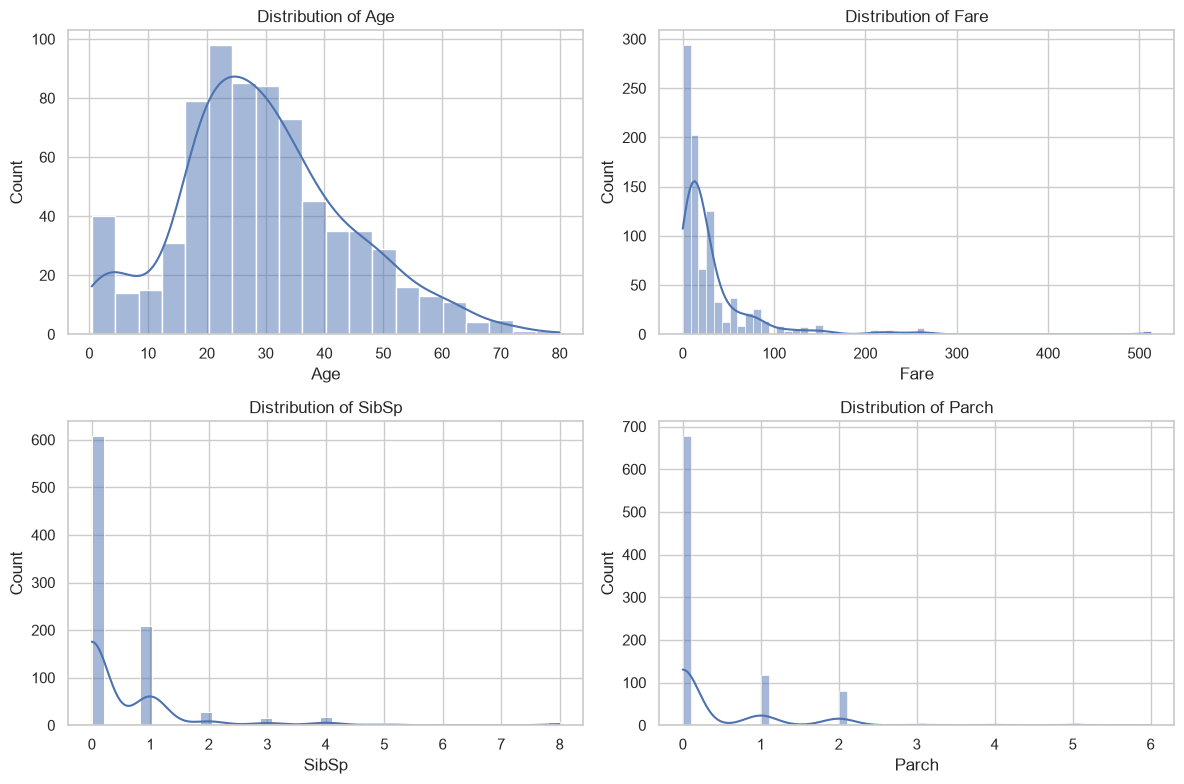

In [7]:
# Histograms and boxplots (Hint 2)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col].dropna(), kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.savefig("images/histograms.png", dpi=150)
plt.show()

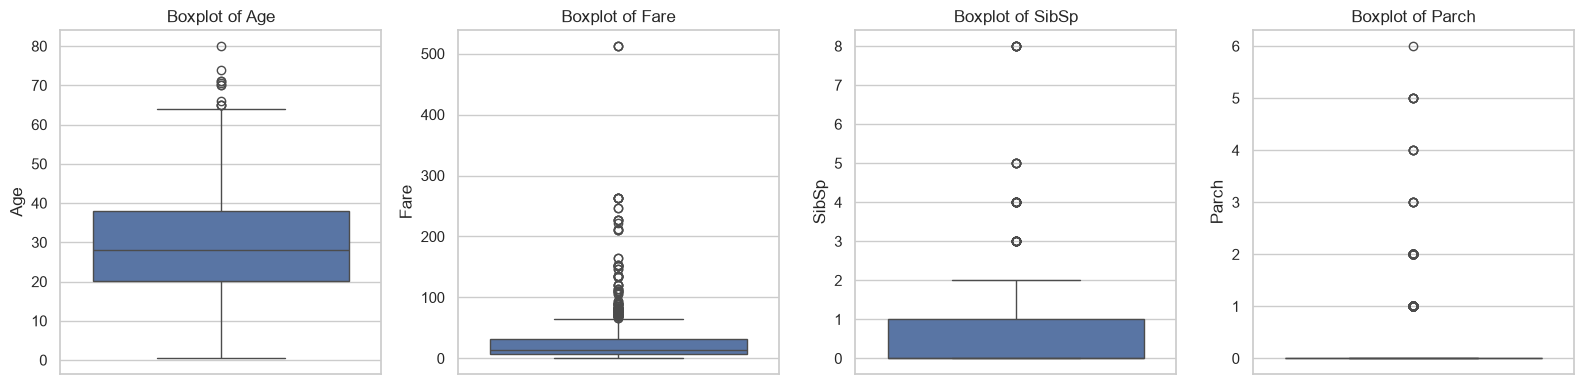

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")
plt.tight_layout()
plt.savefig("images/boxplots.png", dpi=150)
plt.show()

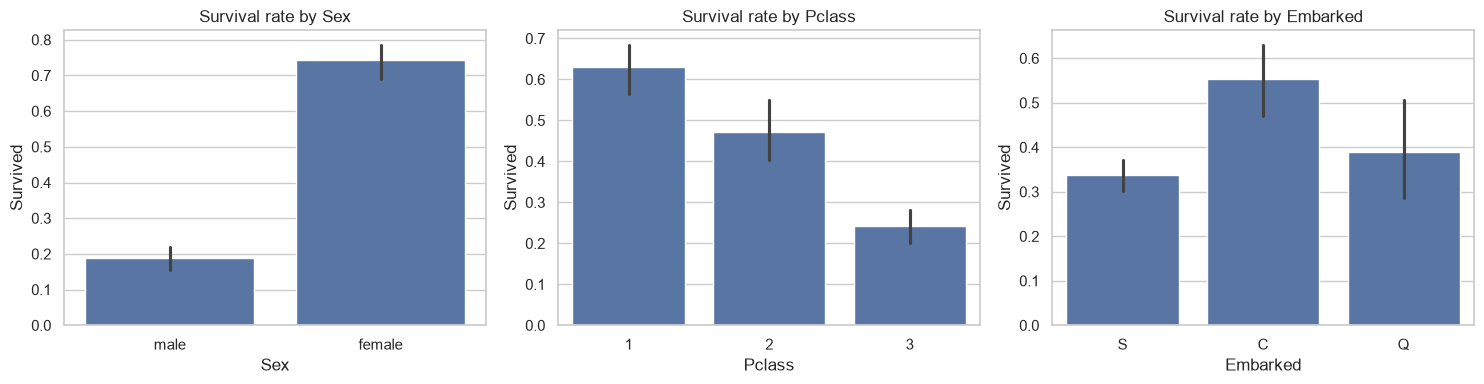

In [9]:
# Categorical features vs survival
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Sex", "Pclass", "Embarked"]):
    sns.barplot(x=col, y="Survived", data=df, ax=ax)
    ax.set_title(f"Survival rate by {col}")
plt.tight_layout()
plt.savefig("images/survival_by_category.png", dpi=150)
plt.show()

In [10]:
for col in ["Sex", "Pclass", "Embarked"]:
    print(df.groupby(col)["Survived"].mean().round(2), "\n")

Sex
female    0.74
male      0.19
Name: Survived, dtype: float64 

Pclass
1    0.63
2    0.47
3    0.24
Name: Survived, dtype: float64 

Embarked
C    0.55
Q    0.39
S    0.34
Name: Survived, dtype: float64 



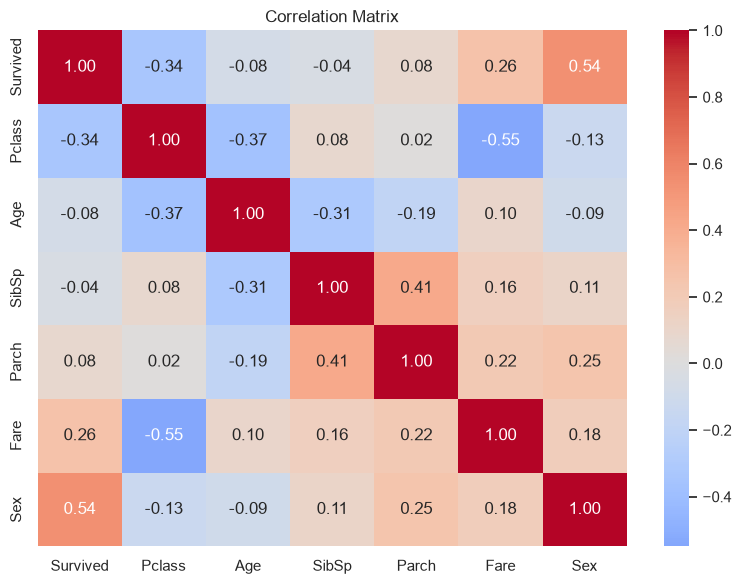

In [11]:
# Correlation matrix and pairplot (Hint 3)
df_corr = df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].copy()
df_corr["Sex"] = df["Sex"].map({"male": 0, "female": 1})
corr = df_corr.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.savefig("images/correlation_heatmap.png", dpi=150)
plt.show()

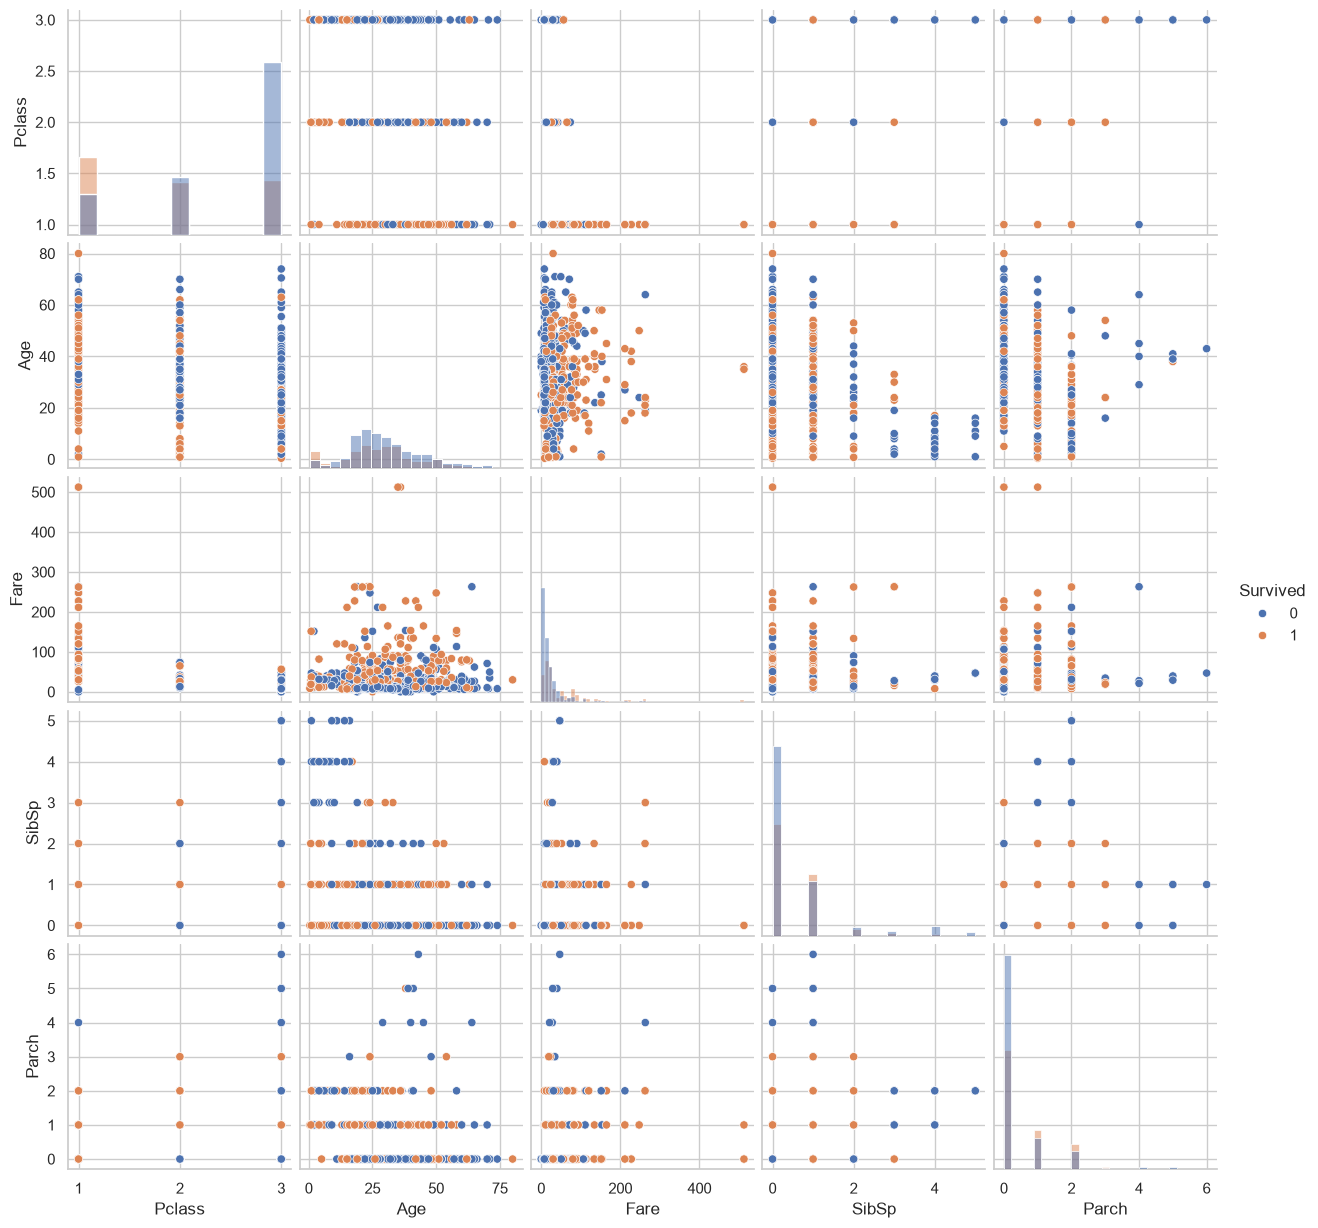

In [12]:
pair_df = df[["Survived", "Pclass", "Age", "Fare", "SibSp", "Parch"]].dropna()
g = sns.pairplot(pair_df, hue="Survived", diag_kind="hist")
g.savefig("images/pairplot.png", dpi=120)
plt.show()

In [13]:
# Patterns, trends and anomalies (Hint 4)

df["AgeGroup"] = pd.cut(df["Age"], bins=[0, 12, 18, 35, 60, 100],
                        labels=["Child", "Teen", "Young Adult", "Adult", "Senior"])
print(df.groupby("AgeGroup", observed=True)["Survived"].mean().round(2))

AgeGroup
Child          0.58
Teen           0.43
Young Adult    0.38
Adult          0.40
Senior         0.23
Name: Survived, dtype: float64


In [14]:
# Anomalies in Fare
print(df["Fare"].nlargest(5))
print("Zero-fare passengers:", (df["Fare"] == 0).sum())
df[df["Fare"] > 300]

258    512.3292
679    512.3292
737    512.3292
27     263.0000
88     263.0000
Name: Fare, dtype: float64
Zero-fare passengers: 15


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,AgeGroup
258,259,1,1,"Ward, Miss. Anna",female,35.0,0,0,PC 17755,512.3292,NaN,C,Young Adult
679,680,1,1,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,0,1,PC 17755,512.3292,B51 B53 B55,C,Adult
737,738,1,1,"Lesurer, Mr. Gustave J",male,35.0,0,0,PC 17755,512.3292,B101,C,Young Adult


In [15]:
# Is missing Age related to class?
print(df.groupby("Pclass")["Age"].apply(lambda s: s.isnull().mean()).round(2))

Pclass
1    0.14
2    0.06
3    0.28
Name: Age, dtype: float64


In [16]:
df["Survived_label"] = df["Survived"].map({0: "No", 1: "Yes"})

fig = px.histogram(df, x="Age", color="Survived_label", barmode="overlay",
                   nbins=30, title="Age distribution by survival")
fig.show()
fig.write_html("images/age_by_survival.html")

In [17]:
fig2 = px.scatter(df, x="Age", y="Fare", color="Survived_label", symbol="Sex",
                  hover_data=["Pclass"], title="Age vs Fare")
fig2.show()
fig2.write_html("images/age_vs_fare.html")

# My inferences
 - Women survived far more often than men.
 - Survival drops with passenger class (1st > 2nd > 3rd).
 - Fare is heavily right-skewed with a few very high fares.
 - Pclass and Fare are negatively correlated, and Sex has the strongest link to Survived.
 - Children had a higher survival rate than other age groups.
 - Age and Cabin have missing values that need handling before modeling.